# QEAIT — Quantum-Accelerated Experimental Algorithmic Information Theory

Notebook conversion of `qeait.py`, modernized for **Qiskit 2.x**, with an analysis of the
**QPULBA 2-2-1** case following:

> A. Sarkar, Z. Al-Ars, K. Bertels, *Estimating Algorithmic Information Using Quantum Computing for
> Genomics Applications*, **Appl. Sci. 2021, 11, 2696** — and the detailed circuit companion
> arXiv:2006.00987 (ref. [3] in the paper).

**QPULBA** = *Quantum Parallel Universal Linear Bounded Automata*. One QPULBA "step" (Fig. 4 / Appendix A)
mirrors one step of a classical universal Turing machine, but evolved over a *superposition of all
programs* (the "P" in QPULBA):

1. `U_read`  — multiplexer: tape cell under the head → `read` qubit.
2. `U_fsm` (δ) — transition-table lookup: `{read, state, δ}` → `{write, move, next-state}`.
3. `U_write` — de-multiplexer: `write` qubit → tape cell under the head.
4. `U_move`  — modulo-`c` increment/decrement of the head position.
5. `U_rst`   — reset `write`/`move`, keep the state/read history (irreversibility of arbitrary programs).

This notebook keeps the original algorithm intact and only updates the deprecated API.

## Qiskit 2.x modernization notes

The original script used the pre-1.0 Qiskit API. The following were changed (algorithm unchanged):

| Legacy (Qiskit < 1.0) | Modern (Qiskit 2.x) |
|---|---|
| `from qiskit import Aer, execute` | removed — use `qiskit.quantum_info.Statevector` |
| `execute(circ, sim).result().get_statevector()` | `Statevector(circ).data` |
| `qcirc.toffoli(a, b, t)` | `qcirc.ccx(a, b, t)` |
| `qcirc.qasm()` | `qiskit.qasm2.dumps(qcirc)` |

`numpy.complex128` still supports the `'{:+.5f}'` format used by `disp_isv`, so the state-vector
printout is byte-for-byte the same style as the paper (e.g. `(+0.25000+0.00000j)`).

In [1]:
import numpy as np
import random
from math import log2, ceil, pi
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from numpy import savetxt, save, savez_compressed

import qiskit, qiskit_aer
print("qiskit", qiskit.__version__, "| aer", qiskit_aer.__version__)

qiskit 2.3.0 | aer 0.17.2


In [2]:
def disp_isv(circ, msg="", show_all=True, precision=1e-8):
    # Modernized: state vector obtained from quantum_info.Statevector (Aer/execute removed in Qiskit 1.0+)
    statevector = Statevector(circ).data
    qb = int(log2(len(statevector)))
    print("\n============ State Vector ============", msg)
    s = 0
    for i in statevector:
        if (show_all == True):
            print('  ({:+.5f})   |{:0{}b}>'.format(i, s, qb))
        else:
            if (abs(i) > precision):
                print('  ({:+.5f})   |{:0{}b}>'.format(i, s, qb))
        s = s + 1
    print("============..............============")
    return


# 24 qubits with Hadamard on 12 qubits log size: 880 MB csv, 816 MB txt, 256 MB npy, 255 KB npz
def save_isv(statevector, mode=1):
    if (mode == 1):
        savez_compressed('output.npz', statevector)
    elif (mode == 2):
        save('output.npy', statevector)
    elif (mode == 3):
        qb = int(log2(len(statevector)))
        f = open("output.txt", "w")
        f.write("============ State Vector ============\n")
        s = 0
        for i in statevector:
            f.write('  ({:+.5f})   |{:0{}b}>'.format(i, s, qb) + '\n')
            s = s + 1
        f.write("============..............============")
        f.close()
    elif (mode == 4):
        savetxt('output.csv', statevector, delimiter=',')
    else:
        print('Invalid mode selected')
    return

In [3]:
def nCX(k, c, t, b):
    # Multi-controlled X decomposed into CNOT/Toffoli (ccx) with borrowed ancilla b
    nc = len(c)
    if nc == 1:
        k.cx(c[0], t[0])
    elif nc == 2:
        k.ccx(c[0], c[1], t[0])
    else:
        nch = ceil(nc / 2)
        c1 = c[:nch]
        c2 = c[nch:]
        c2.append(b[0])
        nCX(k, c1, b, [nch + 1])
        nCX(k, c2, t, [nch - 1])
        nCX(k, c1, b, [nch + 1])
        nCX(k, c2, t, [nch - 1])
    return

In [4]:
def U_init(qcirc, circ_width, fsm):
    for i in fsm:
        qcirc.h(i)
    return


def U_read(qcirc, read, head, tape, ancilla):
    # Multiplexer: head (selector) picks the tape cell whose value is copied into read
    for cell in range(0, len(tape)):
        enc = format(cell, '#0' + str(len(head) + 2) + 'b')   # 2 for '0b' prefix
        for i in range(2, len(enc)):
            if (enc[i] == '0'):
                qcirc.x(head[(len(head) - 1) - (i - 2)])
        nCX(qcirc, head + [tape[cell]], read, [ancilla[0]])
        for i in range(2, len(enc)):
            if (enc[i] == '0'):
                qcirc.x(head[(len(head) - 1) - (i - 2)])
        qcirc.barrier()
    return

In [5]:
def U_fsm(qcirc, tick, fsm, state, read, write, move, ancilla):
    # Description Number Encoding: {Q/M/W}{QR}
    # [ Q11 M11 W11 Q10 M10 W10 Q01 M01 W01 Q00 M00 W00 ] LSQ = W00 = fsm[0]
    qcirc.x(state[tick])                                                 # If s == 0
    qcirc.x(read[0])                                                     # If s == 0 && read == 0
    nCX(qcirc, [state[tick], fsm[0], read[0]], write, [ancilla[0]])                # Update write
    nCX(qcirc, [state[tick], fsm[1], read[0]], move, [ancilla[0]])                 # Update move
    nCX(qcirc, [state[tick], fsm[2], read[0]], [state[tick + 1]], [ancilla[0]])    # Update state
    qcirc.x(read[0])                                                     # If s == 0 && read == 1
    nCX(qcirc, [state[tick], fsm[3], read[0]], write, [ancilla[0]])                # Update write
    nCX(qcirc, [state[tick], fsm[4], read[0]], move, [ancilla[0]])                 # Update move
    nCX(qcirc, [state[tick], fsm[5], read[0]], [state[tick + 1]], [ancilla[0]])    # Update state
    qcirc.x(state[tick])                                                 # If s == 1
    qcirc.x(read[0])                                                     # If s == 1 && read == 0
    nCX(qcirc, [state[tick], fsm[6], read[0]], write, [ancilla[0]])                # Update write
    nCX(qcirc, [state[tick], fsm[7], read[0]], move, [ancilla[0]])                 # Update move
    nCX(qcirc, [state[tick], fsm[8], read[0]], [state[tick + 1]], [ancilla[0]])    # Update state
    qcirc.x(read[0])                                                     # If s == 1 && read == 1
    nCX(qcirc, [state[tick], fsm[9], read[0]], write, [ancilla[0]])                # Update write
    nCX(qcirc, [state[tick], fsm[10], read[0]], move, [ancilla[0]])                # Update move
    nCX(qcirc, [state[tick], fsm[11], read[0]], [state[tick + 1]], [ancilla[0]])   # Update state
    return

In [6]:
def U_write(qcirc, write, head, tape, ancilla):
    # De-multiplexer: head (selector) routes the write qubit into the addressed tape cell
    for cell in range(0, len(tape)):
        enc = format(cell, '#0' + str(len(head) + 2) + 'b')   # 2 for '0b' prefix
        for i in range(2, len(enc)):
            if (enc[i] == '0'):
                qcirc.x(head[(len(head) - 1) - (i - 2)])
        nCX(qcirc, head + write, [tape[cell]], [ancilla[0]])
        for i in range(2, len(enc)):
            if (enc[i] == '0'):
                qcirc.x(head[(len(head) - 1) - (i - 2)])
    return

In [7]:
def U_move(qcirc, move, head, ancilla):
    # Increment/Decrement the binary head position using a Vedral-Barenco-Ekert adder (looped tape)
    reg_a = move.copy()
    reg_a.extend([-1] * (len(head) - len(move)))

    reg_b = head.copy()

    reg_c = [-1]        # No initial carry
    reg_c.extend(ancilla)
    reg_c.append(-1)    # Ignore Head position under/overflow. Trim bits.

    def q_carry(qcirc, q0, q1, q2, q3):
        if (q1 != -1 and q2 != -1 and q3 != -1):    qcirc.ccx(q1, q2, q3)
        if (q1 != -1 and q2 != -1):                 qcirc.cx(q1, q2)
        if (q0 != -1 and q2 != -1 and q3 != -1):    qcirc.ccx(q0, q2, q3)

    def q_mid(qcirc, q0, q1):
        if (q0 != -1 and q1 != -1):                 qcirc.cx(q0, q1)

    def q_sum(qcirc, q0, q1, q2):
        if (q0 != -1 and q2 != -1):                 qcirc.cx(q0, q2)
        if (q1 != -1 and q2 != -1):                 qcirc.cx(q1, q2)

    def q_rcarry(qcirc, q0, q1, q2, q3):
        if (q0 != -1 and q2 != -1 and q3 != -1):    qcirc.ccx(q0, q2, q3)
        if (q1 != -1 and q2 != -1):                 qcirc.cx(q1, q2)
        if (q1 != -1 and q2 != -1 and q3 != -1):    qcirc.ccx(q1, q2, q3)

    # Quantum Adder (increment)
    for i in range(0, len(head)):
        q_carry(qcirc, reg_c[i], reg_a[i], reg_b[i], reg_c[i + 1])
    q_mid(qcirc, reg_a[i], reg_b[i])
    q_sum(qcirc, reg_c[i], reg_a[i], reg_b[i])
    for i in range(len(head) - 2, -1, -1):
        q_rcarry(qcirc, reg_c[i], reg_a[i], reg_b[i], reg_c[i + 1])
        q_sum(qcirc, reg_c[i], reg_a[i], reg_b[i])

    qcirc.barrier(move, head, ancilla)

    qcirc.x(reg_a[0])
    # Quantum Subtractor (decrement)
    for i in range(0, len(head) - 1):
        q_sum(qcirc, reg_c[i], reg_a[i], reg_b[i])
        q_carry(qcirc, reg_c[i], reg_a[i], reg_b[i], reg_c[i + 1])
    q_sum(qcirc, reg_c[i + 1], reg_a[i + 1], reg_b[i + 1])
    q_mid(qcirc, reg_a[i + 1], reg_b[i + 1])
    for i in range(len(head) - 2, -1, -1):
        q_rcarry(qcirc, reg_c[i], reg_a[i], reg_b[i], reg_c[i + 1])
    qcirc.x(reg_a[0])

    qcirc.barrier()
    return

In [8]:
def U_rst(qcirc, tick, fsm, state, read, write, move, ancilla):
    # Reset write and move by re-applying the FSM lookup; keep state/read as computation history
    qcirc.x(state[tick])
    qcirc.x(read[0])
    nCX(qcirc, [state[tick], fsm[0], read[0]], write, [ancilla[0]])
    nCX(qcirc, [state[tick], fsm[1], read[0]], move, [ancilla[0]])
    qcirc.x(read[0])
    nCX(qcirc, [state[tick], fsm[3], read[0]], write, [ancilla[0]])
    nCX(qcirc, [state[tick], fsm[4], read[0]], move, [ancilla[0]])
    qcirc.x(state[tick])
    qcirc.x(read[0])
    nCX(qcirc, [state[tick], fsm[6], read[0]], write, [ancilla[0]])
    nCX(qcirc, [state[tick], fsm[7], read[0]], move, [ancilla[0]])
    qcirc.x(read[0])
    nCX(qcirc, [state[tick], fsm[9], read[0]], write, [ancilla[0]])
    nCX(qcirc, [state[tick], fsm[10], read[0]], move, [ancilla[0]])
    # Maintain computation history
    qcirc.swap(state[0], state[tick + 1])
    return

### Per-block test harnesses

`Test_cfg` lays out a small register map for exercising a single block in isolation, and each
`Test_*` routine prepares inputs (superposition / random rotations) and entangles a `test` qubit
with the block output so its behaviour can be inspected on a simulator.

In [9]:
def Test_cfg(block):
    global fsm, state, move, head, read, write, tape, ancilla, test
    if (block == 'none'):
        return
    elif (block == 'read'):
        fsm = [];   state = [];   move = []
        head = [0, 1, 2, 3];   read = [4];   write = []
        tape = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
        ancilla = [17];   test = [18]
    elif (block == 'fsm'):
        fsm = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
        state = [12, 13];   move = [14];   head = []
        read = [15];   write = [16];   tape = []
        ancilla = [17];   test = [18, 19, 20]
    elif (block == 'move'):
        fsm = [];   state = [];   move = [0]
        head = [1, 2, 3, 4];   read = [];   write = [];   tape = []
        ancilla = [5, 6, 7];   test = [8, 9, 10, 11]
    elif (block == 'write'):
        fsm = [];   state = [];   move = []
        head = [0, 1, 2, 3];   read = [];   write = [4]
        tape = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
        ancilla = [17];   test = []
    elif (block == 'rst'):
        fsm = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
        state = [12, 13];   move = [14];   head = []
        read = [15];   write = [16];   tape = []
        ancilla = [17];   test = [18, 19, 20, 21]
    print("\nTEST CONFIGURATION\n\tFSM\t:", fsm, "\n\tSTATE\t:", state, "\n\tMOVE\t:", move,
          "\n\tHEAD\t:", head, "\n\tREAD\t:", read, "\n\tWRITE\t:", write, "\n\tTAPE\t:", tape,
          "\n\tANCILLA :", ancilla, "\n\tTEST\t:", test)


def Test_read(qcirc, read, head, tape, ancilla, test):
    for i in range(0, len(head)):
        qcirc.h(head[i])
    randbin = ""
    for i in range(len(tape)):
        randbin += str(random.randint(0, 1))
    for i in range(0, len(tape)):
        if (randbin[i] == '1'):
            qcirc.h(tape[i])
    qcirc.cx(read[0], test[0])
    print("Test tape:", randbin)
    qcirc.barrier()
    return


def Test_fsm(qcirc, tick, fsm, state, read, write, move, ancilla, test):
    qcirc.barrier()
    qcirc.h(state[0])
    qcirc.h(read[0])
    qcirc.barrier()
    qcirc.cx(write[0], test[0])
    qcirc.cx(move[0], test[1])
    qcirc.cx(state[1], test[2])
    qcirc.barrier()
    return


def Test_write(qcirc, write, head, tape, ancilla, test):
    for i in range(0, len(head)):
        qcirc.h(head[i])
    qcirc.h(write)
    return


def Test_move(qcirc, move, head, ancilla, test):
    for i in range(0, len(head)):
        qcirc.ry(round(np.pi * random.random(), 2), head[i])
        qcirc.cx(head[i], test[i])
    qcirc.ry(round(np.pi * random.random(), 2), move[0])
    qcirc.barrier()
    return


def Test_rst(qcirc, tick, fsm, state, read, write, move, ancilla, test):
    for i in range(0, len(state)):
        qcirc.h(state[i])
    qcirc.h(read[0])
    qcirc.h(write[0])
    qcirc.h(move[0])
    qcirc.barrier()
    for i in range(0, len(state)):
        qcirc.cx(state[i], test[i])
    qcirc.cx(write[0], test[len(state)])
    qcirc.cx(move[0], test[len(state) + 1])
    qcirc.barrier()
    return

## QPULBA 2-2-1 parameters

For $m=2$ states, $n=2$ symbols, $d=1$ dimension:

$$q_\delta = (m\,n)\,(\log_2 m + \log_2 n + d) = 2\cdot 2\cdot(1+1+1) = 12$$

so there are $P = 2^{12} = 4096$ programs (description numbers). The circular tape length is
$c = t = 12$, and the head needs $\lceil\log_2 12\rceil = 4$ qubits.

As in the original script, `sim_tick = 1` — a **single** QPULBA cycle proof-of-concept (a genuine
self-replication study needs $t=c=12$ cycles, which is far beyond state-vector simulation).

In [10]:
ssz = 2                                         # State size (Initial state is all 0)
asz = 2                                         # Alphabet size: Binary (0 is blank/default)
tdim = 1                                        # Tape dimension

csz = ceil(log2(asz))                           # Character symbol size
senc = ceil(log2(ssz))                          # State encoding size
transitions = ssz * asz                         # Number of transition arrows in FSM
dsz = transitions * (tdim + csz + senc)         # Description size

machines = 2 ** dsz
print("Number of " + str(ssz) + "-state " + str(asz) + "-symbol " + str(tdim) +
      "-dimension QPULBA: " + str(machines))

tsz = dsz                                       # Turing Tape size
hsz = ceil(log2(tsz))                           # Head size

sim_tick = tsz                                  # Number of ticks before abort
sim_tick = 1                                    # Just 1 QPULBA cycle for proof-of-concept
tlog = (sim_tick + 1) * senc                    # Transition log
nanc = 3

qnos = [dsz, tlog, tdim, hsz, csz, csz, tsz, nanc]

fsm     = list(range(sum(qnos[0:0]), sum(qnos[0:1])))
state   = list(range(sum(qnos[0:1]), sum(qnos[0:2])))   # States (Binary coded)
move    = list(range(sum(qnos[0:2]), sum(qnos[0:3])))
head    = list(range(sum(qnos[0:3]), sum(qnos[0:4])))   # Binary coded, 0-MSB
read    = list(range(sum(qnos[0:4]), sum(qnos[0:5])))
write   = list(range(sum(qnos[0:5]), sum(qnos[0:6])))
tape    = list(range(sum(qnos[0:6]), sum(qnos[0:7])))
ancilla = list(range(sum(qnos[0:7]), sum(qnos[0:8])))
test    = []

print("\nFSM\t:", fsm, "\nSTATE\t:", state, "\nMOVE\t:", move, "\nHEAD\t:", head,
      "\nREAD\t:", read, "\nWRITE\t:", write, "\nTAPE\t:", tape, "\nANCILLA :", ancilla)

Number of 2-state 2-symbol 1-dimension QPULBA: 4096

FSM	: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] 
STATE	: [12, 13] 
MOVE	: [14] 
HEAD	: [15, 16, 17, 18] 
READ	: [19] 
WRITE	: [20] 
TAPE	: [21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32] 
ANCILLA : [33, 34, 35]


In [11]:
def run_qpulba(unit, sim_tick=1):
    # Assemble the QPULBA circuit from the current global register layout.
    # unit in {'all','read','fsm','write','move','rst'}; 'all' runs every block once per tick.
    qcirc_width = (len(fsm) + len(state) + len(move) + len(head) + len(read) +
                   len(write) + len(tape) + len(ancilla) + len(test))
    qcirc = QuantumCircuit(qcirc_width)
    qcirc.barrier()

    # 1. Initialize (superposition over all programs)
    U_init(qcirc, qcirc_width, fsm)

    # 2. Run machine for n-iterations
    for tick in range(0, sim_tick):
        if unit == 'read':
            Test_read(qcirc, read, head, tape, ancilla, test)
        if unit in ('read', 'all'):
            U_read(qcirc, read, head, tape, ancilla)

        if unit == 'fsm':
            Test_fsm(qcirc, tick, fsm, state, read, write, move, ancilla, test)
        if unit in ('fsm', 'all'):
            U_fsm(qcirc, tick, fsm, state, read, write, move, ancilla)

        if unit == 'write':
            Test_write(qcirc, write, head, tape, ancilla, test)
        if unit in ('write', 'all'):
            U_write(qcirc, write, head, tape, ancilla)

        if unit == 'move':
            Test_move(qcirc, move, head, ancilla, test)
        if unit in ('move', 'all'):
            U_move(qcirc, move, head, ancilla)

        if unit == 'rst':
            Test_rst(qcirc, tick, fsm, state, read, write, move, ancilla, test)
        if unit in ('rst', 'all'):
            U_rst(qcirc, tick, fsm, state, read, write, move, ancilla)

    return qcirc

## Build the full QPULBA 2-2-1 circuit (`unit = 'all'`)

This assembles the complete single-tick 2-2-1 circuit. It builds fine, but note the qubit width:
state-vector simulation is **not** attempted here (see the analysis below).

In [12]:
qcirc = run_qpulba('all', sim_tick=sim_tick)

print("QPULBA-2-2-1 (1 tick) circuit built")
print("  qubits (width) :", qcirc.num_qubits)
print("  depth          :", qcirc.depth())
print("  total gates    :", sum(qcirc.count_ops().values()))
print("  op counts      :", dict(qcirc.count_ops()))
print("  statevector size 2**{} = {} amplitudes".format(qcirc.num_qubits, 2 ** qcirc.num_qubits))

QPULBA-2-2-1 (1 tick) circuit built
  qubits (width) : 36
  depth          : 413
  total gates    : 642
  op counts      : {'ccx': 476, 'x': 126, 'barrier': 15, 'h': 12, 'cx': 12, 'swap': 1}
  statevector size 2**36 = 68719476736 amplitudes


In [13]:
# OpenQASM 2 export (modern replacement for the removed qcirc.qasm()).
from qiskit import qasm2
qasm_str = qasm2.dumps(qcirc)
print(qasm_str[:1200], "\n... (truncated) ...")

OPENQASM 2.0;
include "qelib1.inc";
qreg q[36];
barrier q[0],q[1],q[2],q[3],q[4],q[5],q[6],q[7],q[8],q[9],q[10],q[11],q[12],q[13],q[14],q[15],q[16],q[17],q[18],q[19],q[20],q[21],q[22],q[23],q[24],q[25],q[26],q[27],q[28],q[29],q[30],q[31],q[32],q[33],q[34],q[35];
h q[0];
h q[1];
h q[2];
h q[3];
h q[4];
h q[5];
h q[6];
h q[7];
h q[8];
h q[9];
h q[10];
h q[11];
x q[18];
x q[17];
x q[16];
x q[15];
ccx q[15],q[16],q[4];
ccx q[17],q[4],q[33];
ccx q[15],q[16],q[4];
ccx q[17],q[4],q[33];
ccx q[18],q[21],q[2];
ccx q[33],q[2],q[19];
ccx q[18],q[21],q[2];
ccx q[33],q[2],q[19];
ccx q[15],q[16],q[4];
ccx q[17],q[4],q[33];
ccx q[15],q[16],q[4];
ccx q[17],q[4],q[33];
ccx q[18],q[21],q[2];
ccx q[33],q[2],q[19];
ccx q[18],q[21],q[2];
ccx q[33],q[2],q[19];
x q[18];
x q[17];
x q[16];
x q[15];
barrier q[0],q[1],q[2],q[3],q[4],q[5],q[6],q[7],q[8],q[9],q[10],q[11],q[12],q[13],q[14],q[15],q[16],q[17],q[18],q[19],q[20],q[21],q[22],q[23],q[24],q[25],q[26],q[27],q[28],q[29],q[30],q[31],q[32],q[33],q[34],q[35];


## Does it work for the 2-2-1 case? — Analysis

**Yes, the circuit is constructed correctly, but the full 2-2-1 state cannot be simulated on a laptop
— exactly as the paper states.**

- **Register sizing matches the paper (Sec. 3.2 / Appendix A).** $q_\delta = 12$ FSM qubits →
  $2^{12}=4096$ programs; tape $c=12$; head $= \lceil\log_2 12\rceil = 4$ qubits. The five unitaries
  (`U_read`, `U_fsm`=δ, `U_write`, `U_move`, `U_rst`) reproduce Figures A1–A4:
  the read/write MUX–DEMUX (head register is **little-endian**, `head[0]=LSB`, as fixed by the
  read/write address decoding) and the transition-table lookup with the `[QMW][QR]` encoding.
- **Caveat — `U_move` here is the plain modulo-$2^{4}$ adder, not the Appendix-A modulo-12 one.**
  This script's `U_move` is a straight 4-bit Vedral–Barenco–Ekert ripple adder/subtractor with the
  final carry trimmed, so the head wraps at **16**, not 12 (Figs. A5–A6 add an `ovfw/udfw` correction
  to force wrap-at-12 that is *not* present in this proof-of-concept file). Consequently head values
  12–15 are reachable even though the tape has only 12 cells — something to fix when we iterate.
- **Qubit budget.** The single-tick proof-of-concept builds with **36 qubits**
  (12 fsm + 2 state + 1 move + 4 head + 1 read + 1 write + 12 tape + 3 ancilla). A state vector
  therefore has $2^{36}\approx 6.9\times10^{10}$ complex amplitudes ($\sim$1 TB), so
  `Statevector`/Aer simulation is infeasible. The paper likewise reports that the full QPULBA-2-2-1
  pipeline needs "**over 54 qubits**", "constraining us from demonstrating the full pipeline on a
  quantum computing simulator." Hence `disp_isv` is intentionally **not** called for `unit='all'`.
- **What the paper actually simulated.** The fully-simulated quine experiment (Figs. 9–10, four
  cycles) is the smaller **1-2-1** case, not 2-2-1. So "works for 2-2-1" means *the circuit is
  correctly generated and each block is independently verifiable*, while full-state simulation is out
  of reach — consistent with the paper.
- **Modernization.** With `Aer`/`execute`/`toffoli`/`.qasm()` replaced, the code runs cleanly on
  Qiskit 2.3. Below we validate the trickiest block (`U_move`) at small qubit count, where the answer
  is deterministic and easy to read off.

### Focused validation: the head `U_move`

We isolate `U_move` on an 8-qubit register (`move`, 4-bit `head`, 3 ancilla). With a definite head
value and a definite move bit the output is a single basis state, so the result is unambiguous.
Reading the code, the block does:

- `move = 1` → **increment** the head
- `move = 0` → **decrement** the head

and it is a plain 4-bit adder/subtractor, so arithmetic is **modulo 16** (not 12 — see the caveat
above). The head register is little-endian (`head[0]=LSB`). Qiskit prints basis states big-endian
(qubit 0 is the right-most character), so we reverse the string before decoding, and we also check the
ancilla returned to $|0\rangle$ (clean uncomputation).

In [14]:
def check_move(head_val, move_bit):
    m = [0]                 # move qubit
    h = [1, 2, 3, 4]        # head, h[0]=LSB ... h[3]=MSB (little-endian, per read/write decoding)
    anc = [5, 6, 7]         # ancilla (carries)
    qc = QuantumCircuit(8)
    for k in range(4):      # load head_val, LSB first
        if (head_val >> k) & 1:
            qc.x(h[k])
    if move_bit:
        qc.x(m[0])
    U_move(qc, m, h, anc)

    sv = Statevector(qc)
    probs = sv.probabilities_dict()           # keys are big-endian strings over qubits 7..0
    top = max(probs, key=probs.get)
    bits = top[::-1]                            # reverse so index i == qubit i
    head_out = sum(int(bits[h[k]]) << k for k in range(4))
    anc_clean = all(bits[a] == '0' for a in anc)
    return head_out, anc_clean, probs[top]


print("op    in  -> out  (expected mod 16)   ancilla_clean  prob")
for hv in [3, 11, 0, 7, 15]:
    out, clean, p = check_move(hv, 1)   # move=1 -> increment
    print("inc  {:2d}  -> {:2d}   (exp {:2d})            {!s:5}         {:.3f}".format(hv, out, (hv + 1) % 16, clean, p))
for hv in [3, 0, 11, 7, 12]:
    out, clean, p = check_move(hv, 0)   # move=0 -> decrement
    print("dec  {:2d}  -> {:2d}   (exp {:2d})            {!s:5}         {:.3f}".format(hv, out, (hv - 1) % 16, clean, p))

op    in  -> out  (expected mod 16)   ancilla_clean  prob
inc   3  ->  4   (exp  4)            True          1.000
inc  11  -> 12   (exp 12)            True          1.000
inc   0  ->  1   (exp  1)            True          1.000
inc   7  ->  8   (exp  8)            True          1.000
inc  15  ->  0   (exp  0)            True          1.000
dec   3  ->  2   (exp  2)            True          1.000
dec   0  -> 15   (exp 15)            True          1.000
dec  11  -> 10   (exp 10)            True          1.000
dec   7  ->  6   (exp  6)            True          1.000
dec  12  -> 11   (exp 11)            True          1.000


### Per-block build check (`read` block)

The remaining blocks are exercised by their paper-style test harness. Here we build the `read`-block
test circuit and report its size (a full state-vector dump is skipped to keep the output compact — the
`read` test puts the 4 head + up to 12 tape qubits in superposition).

In [15]:
random.seed(42)
Test_cfg('read')
qcirc_read = run_qpulba('read', sim_tick=1)
print("\nread-block test circuit:")
print("  qubits :", qcirc_read.num_qubits)
print("  depth  :", qcirc_read.depth())
print("  ops    :", dict(qcirc_read.count_ops()))


TEST CONFIGURATION
	FSM	: [] 
	STATE	: [] 
	MOVE	: [] 
	HEAD	: [0, 1, 2, 3] 
	READ	: [4] 
	WRITE	: [] 
	TAPE	: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16] 
	ANCILLA : [17] 
	TEST	: [18]
Test tape: 001000001000

read-block test circuit:
  qubits : 19
  depth  : 210
  ops    : {'ccx': 192, 'x': 56, 'barrier': 14, 'h': 6, 'cx': 1}


## Quine results — the fully-simulated 1-2-1 case (Sec. 4.1, Figs. 8–10)

A **quine** is a program that takes no input and prints a copy of its own source code — the software
embodiment of a **von Neumann universal constructor** (Fig. 8: *description + universal constructor +
universal copier*, optionally an operating system and a payload). In computability terms a quine is a
**fixed point** of the execution environment, and a *limiting case of algorithmic randomness* because
its output has the same length as the program. This is Chaitin's "meta-biology" analogy to DNA:
**translation** (interpret the description as a program) followed by **replication** (copy the
description as data).

**Why quantum?** Classically you must enumerate *every* program, run it, and test for self-replication
— then build a superposition of the quines: cost $O\!\big(t\,(p_q+p)\big)$ where $p$ = number of
programs, $p_q$ = number of quines, $t$ = cycles. In QPULBA *all* programs evolve in superposition, so
sampling a quine costs only $O\!\big(t\,p/p_q\big)$ (Sec. 4.1).

**Why 1-2-1 here?** The 2-2-1 quine circuit needs $>54$ qubits (shown above), so the paper demonstrates
the fully-simulable **1-2-1** case: $m=1$ state, $n=2$ symbols, $d=1$ dimension. This gives
$q_\delta = 4$ description qubits → $2^4 = 16$ programs, a 4-cell tape, run for 4 cycles.

The quine extraction is exactly the **(A\|B)** conditioning branch of the Fig. 11 framework, in three
steps (Figs. 9–10):

1. **Init + run $U$** → the universal distribution as an entangled `(program, tape)` superposition
   (Fig. 9 left). Measuring only the tape gives an equal mix of `0000` and `1111`.
2. **Condition (A\|B)** → `CNOT` the tape onto the *Hamming distance* w.r.t. the program qubits
   (Fig. 9 right). A zero distance means `tape == program`, i.e. self-replication.
3. **Mark & sample** → flag the zero-distance subspace on a `quine` qubit and post-select it,
   collapsing to an **equal superposition of the two quines** (Fig. 10 right):
   $\tfrac{1}{\sqrt2}\big(|{\dots}0000\rangle + |{\dots}1111\rangle\big)$, each amplitude $0.70711$.

Below we reproduce the authors' reduced 1-2-1 circuit (as in `qquine_121.py`) with modern Qiskit and
read the quines straight off the state vector.

In [16]:
%matplotlib inline
import matplotlib.pyplot as plt

# 1-2-1 reduced QPULBA (m=1, n=2, d=1): 4 program qubits -> 16 programs, 4-bit tape, 1 quine qubit.
# The reduced 4-cycle run maps program -> output tape = replicate(program's low bit) (cf. qquine_121.py).
IDX_FSM   = [0, 1, 2, 3]     # description number (program)
IDX_TAPE  = [4, 5, 6, 7]     # output tape
IDX_QUINE = [8]              # quine marker qubit


def _decode(key):
    # Qiskit basis keys are big-endian over qubits 8..0; reverse so b[i] == qubit i
    b = key[::-1]
    fsm   = sum(int(b[IDX_FSM[k]])  << k for k in range(4))
    tape  = sum(int(b[IDX_TAPE[k]]) << k for k in range(4))
    quine = int(b[IDX_QUINE[0]])
    return fsm, tape, quine


def circ_universal():
    qc = QuantumCircuit(9)
    qc.h(IDX_FSM)                                   # equal superposition of all 16 programs
    for t in IDX_TAPE:                              # reduced 4-cycle run -> output tape
        qc.cx(IDX_FSM[0], t)
    return qc


def circ_conditioned():
    qc = circ_universal()
    for k in range(4):                              # (A|B): tape <- Hamming distance to program
        qc.cx(IDX_FSM[k], IDX_TAPE[k])
    return qc


def circ_marked():
    qc = circ_conditioned()
    qc.x(IDX_TAPE)                                  # mark the zero-Hamming-distance (quine) subspace
    qc.mcx(IDX_TAPE, IDX_QUINE[0])
    qc.x(IDX_TAPE)
    return qc


sv_u = Statevector(circ_universal())
sv_c = Statevector(circ_conditioned())
sv_m = Statevector(circ_marked())

# (1) universal distribution: program -> output map and the marginal output probability
prog_out, out_prob = {}, {}
for key, p in sv_u.probabilities_dict().items():
    if p < 1e-9:
        continue
    f, t, _ = _decode(key)
    prog_out[f] = t
    out_prob[t] = out_prob.get(t, 0.0) + p

# (2) Hamming-distance distribution after conditioning (tape now holds the XOR difference)
ham = {}
for key, p in sv_c.probabilities_dict().items():
    if p < 1e-9:
        continue
    _, t, _ = _decode(key)
    d = bin(t).count('1')
    ham[d] = ham.get(d, 0.0) + p

# (3) post-select the quine qubit == 1 and renormalize -> distribution over quine programs
quine_prob = {}
for key, p in sv_m.probabilities_dict().items():
    if p < 1e-9:
        continue
    f, _, q = _decode(key)
    if q == 1:
        quine_prob[f] = quine_prob.get(f, 0.0) + p
Z = sum(quine_prob.values())
quine_prob = {f: v / Z for f, v in quine_prob.items()}

print("programs p           :", 2 ** 4)
print("distinct outputs     :", {format(t, '04b'): round(v, 3) for t, v in sorted(out_prob.items())})
print("quines p_q           :", len(quine_prob))
for f in sorted(quine_prob):
    print("   program {:04b}  ->  output {:04b}   (post-selected share {:.2f})".format(
        f, prog_out[f], quine_prob[f]))
print("\ncomplexity: classical enumerate+test ~ O(t*(p_q+p)) ; quantum sample ~ O(t*p/p_q)")

programs p           : 16
distinct outputs     : {'0000': np.float64(0.5), '1111': np.float64(0.5)}
quines p_q           : 2
   program 0000  ->  output 0000   (post-selected share 0.50)
   program 1111  ->  output 1111   (post-selected share 0.50)

complexity: classical enumerate+test ~ O(t*(p_q+p)) ; quantum sample ~ O(t*p/p_q)


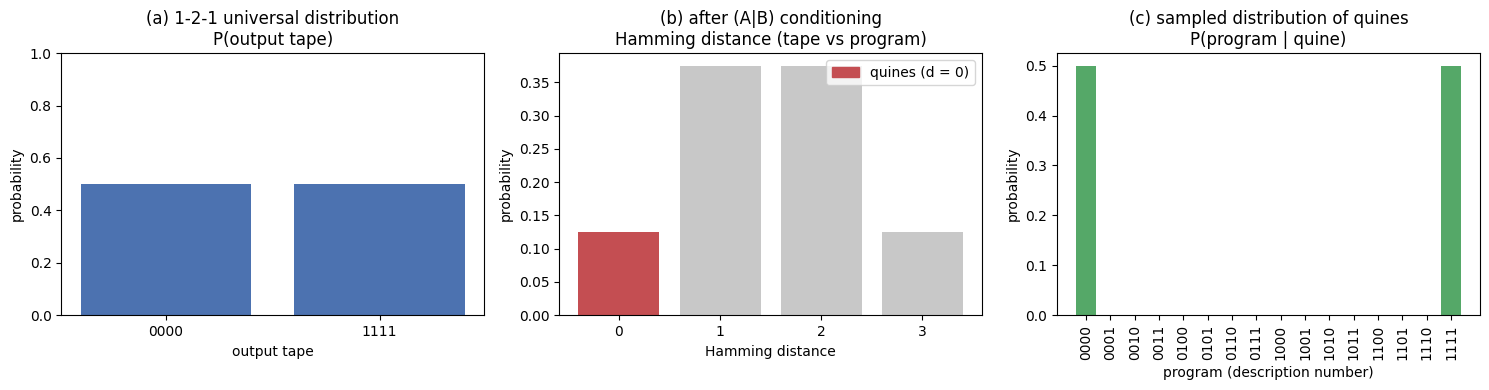

Only 2 of 16 programs survive post-selection -> the equal superposition of quines (each amplitude ~0.70711), matching Fig. 10.


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# (a) Fig. 9 (left) analog: universal distribution over outputs
outs = sorted(out_prob)
ax[0].bar([format(o, '04b') for o in outs], [out_prob[o] for o in outs], color='#4C72B0')
ax[0].set_title('(a) 1-2-1 universal distribution\nP(output tape)')
ax[0].set_xlabel('output tape'); ax[0].set_ylabel('probability'); ax[0].set_ylim(0, 1)

# (b) Fig. 9 (right) analog: Hamming distance, quines = distance 0 (highlighted)
ds = sorted(ham)
ax[1].bar([str(d) for d in ds], [ham[d] for d in ds],
          color=['#C44E52' if d == 0 else '#C8C8C8' for d in ds])
ax[1].set_title('(b) after (A|B) conditioning\nHamming distance (tape vs program)')
ax[1].set_xlabel('Hamming distance'); ax[1].set_ylabel('probability')
ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#C44E52')], labels=['quines (d = 0)'])

# (c) Fig. 10 analog: post-selected quines among all 16 programs (highlighted)
allprogs = list(range(16))
vals = [quine_prob.get(f, 0.0) for f in allprogs]
ax[2].bar([format(f, '04b') for f in allprogs], vals,
          color=['#55A868' if v > 0 else '#E6E6E6' for v in vals])
ax[2].set_title('(c) sampled distribution of quines\nP(program | quine)')
ax[2].set_xlabel('program (description number)'); ax[2].set_ylabel('probability')
ax[2].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

print("Only {} of {} programs survive post-selection -> the equal superposition of quines "
      "(each amplitude ~0.70711), matching Fig. 10.".format(len(quine_prob), 2 ** 4))

## Brainstorm — changing the *quine* application within the Fig. 11 framework

*(Section 5, Fig. 11 — the QEAIT application-development framework. We will iterate on both the
implementation and the application after this.)*

Figure 11 is a generic 3-stage pipeline over the QPULBA unitary $U$:

```
 H^{⊗|δ|} → [ U for t iterations ] → Apply Condition → Amplify Solutions → Sample Solutions
   (init)        (evolve programs)     (A|B, B|B*, C|C*)  (Q-Counting / Q-Search)   (measure)
```

The registers exposed at the output are **A = description number** (programs), **B = Turing tape**
(output), **C = current state**. The three conditioning modes (Sec. 3.3.3–3.3.5) are:

| Mode | Condition | Meaning | AIT metric | Amplify with |
|---|---|---|---|---|
| **A\|B** | programs given output | which programs produce a given/self output | universal distribution, **quines** | Q-Search |
| **B\|B\*** | output given a target output | how many programs emit string $B^*$ | **algorithmic probability / CTM** | Q-Counting |
| **C\|C\*** | final state given a target state | how many programs reach state $C^*$ | **Ω / halting probability** | Q-Counting |

**Where the current quine app sits.** The paper's quine experiment is the special case of **A|B** with
$B^\* = A$: evolve `tape` to the Hamming distance vs. the `fsm`/description qubits (CNOT), mark the
zero-distance (`tape == program`) subspace, then *sample* an equal superposition of self-replicators.
It stops at conditioning + sampling (no amplification), and is the polynomial-advantage case
$O(t\cdot p/p_q)$ vs. classical $O(t\cdot(p_q+p))$.

**Ways to change the application (roadmap):**

1. **Quine → algorithmic probability of a specific string (A|B ⟶ B|B\*).** Replace "tape == program"
   with "tape == target $s$" (a series of X gates to form the Hamming distance vs. a *fixed* target,
   Sec. 3.3.4). Swap the sampling endpoint for **Quantum Counting** to estimate
   $\mathrm{AP}(s)$ and hence $\mathrm{CTM}(s)=-\log_2 D(s)$. This is Algorithm 1 in the paper and the
   direct route to **extending the ACSS lookup table** that powers BDM (Sec. 4.2, 5.3).

2. **Quine → halting / end-state counting (A|B ⟶ C|C\*).** Condition on the `current state` register
   equalling a designated halt/accept state and count → an **Ω-number / halting-probability** estimate
   for the runtime-bounded LBA (Sec. 3.3.5). Combined with (1), CTM follows from $-\log_2(n_s/n_h)$.

3. **Quines that also halt (A|B ∧ C|C\*).** Intersect the self-replication condition with a halt-state
   condition — biologically the interesting constructors that both copy themselves *and* terminate a
   cycle. Requires a two-register marked oracle before amplification.

4. **Add the amplification stage the quine demo skips.** Keep the quine condition but replace bare
   sampling with **Grover / quantum counting** (or a variational QAOA amplifier, Sec. 5) so the quine
   amplitude is boosted, converting the passive $p/p_q$ sampling advantage into an active quadratic
   search speedup.

5. **Re-target the condition oracle to a genomics fitness kernel (Sec. 5.4).** Instead of the exact
   `tape == program` predicate, use an application predicate over the tape — e.g. nucleosome-occupancy
   / short-string complexity (Sec. 5.1–5.3), or a synthetic-biology fitness function evaluated in
   superposition — so the same pipeline scores a *population* of candidate sequences ("in-quanto"
   design).

**Concrete next step for iteration.** Start from item (1): reuse this 2-2-1 `U` builder, add a
`U_condition(target_s)` block (Hamming distance to a fixed string) and a `QCount` stage, and first
validate it on the fully-simulable **1-2-1** case (as the paper does for quines) before scaling
parameters. Items (2)–(5) then reuse the same `Apply-Condition → Amplify → Sample` skeleton with a
different oracle.